# Coding Test #1

I'll start this test using customers-100000.csv with 100,000 rows. I'll analyze all of this collumns.

In [1]:
import time
import tracemalloc
from contextlib import contextmanager

import pandas as pd

PATH = r"D:\personal-project\food-online-test\data\customers-100000.csv"

# List to save every measurement, it will be saved as csv at the end for question number 3
results = []

# Function to measure the time & peak memory of the code inside the "with" block
# tracemalloc makes pandas slower, so use memory=False to get the real time
@contextmanager
def track(label, memory=True):
    if memory:
        tracemalloc.start()
    start_time = time.time()
    yield
    end_duration = time.time() - start_time

    peak_mb = None
    if memory:
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        peak_mb = round(peak / 1e6, 1)

    results.append({"label": label, "peak_mb": peak_mb, "time_s": round(end_duration, 2)})
    print(f"[{label}] peak memory: {peak_mb} MB | time: {round(end_duration, 2)} seconds")

In [2]:
# Read the csv 2 times: first only for the time, second for the peak memory
with track("read csv (time only)", memory=False):
    df = pd.read_csv(PATH)

with track("read csv"):
    df = pd.read_csv(PATH)

print("------------------------")
print("Data Shape (row, column): ", df.shape)
print("DataFrame size after loading: ", round(df.memory_usage(deep=True).sum() / 1e6, 1), "MB")

[read csv (time only)] peak memory: None MB | time: 0.5 seconds


[read csv] peak memory: 54.8 MB | time: 1.16 seconds
------------------------
Data Shape (row, column):  (100000, 12)


DataFrame size after loading:  70.2 MB


In [3]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   Index              100000 non-null  int64 
 1   Customer Id        100000 non-null  object
 2   First Name         100000 non-null  object
 3   Last Name          100000 non-null  object
 4   Company            100000 non-null  object
 5   City               100000 non-null  object
 6   Country            100000 non-null  object
 7   Phone 1            100000 non-null  object
 8   Phone 2            100000 non-null  object
 9   Email              100000 non-null  object
 10  Subscription Date  100000 non-null  object
 11  Website            100000 non-null  object
dtypes: int64(1), object(11)
memory usage: 66.9 MB


## Data Quality

Based on this result, the dataset has 100,000 rows and 12 columns. We continue the analysis by checking the overall data quality first, then each column individually.

In [4]:
with track("data quality"):
    quality = pd.DataFrame({
        "missing": df.isna().sum(),
        "unique_values": df.nunique(),
        "unique_ratio_pct": (df.nunique() / len(df) * 100).round(2),
    }).sort_values("unique_ratio_pct", ascending=False)
    duplicate_rows = df.duplicated().sum()
    duplicate_id = df["Customer Id"].duplicated().sum()

print("------------------------")
display(quality)
print("------------------------")
print("Duplicate rows       :", duplicate_rows)
print("Duplicate Customer Id:", duplicate_id)

[data quality] peak memory: 13.7 MB | time: 0.7 seconds
------------------------


,missing,unique_values,unique_ratio_pct
Index,0,100000,100.00
Customer Id,0,100000,100.00
Phone 2,0,100000,100.00
Phone 1,0,100000,100.00
Email,0,99995,100.00
Company,0,71994,71.99
Website,0,50471,50.47
City,0,49154,49.15
Last Name,0,1000,1.00
Subscription Date,0,880,0.88


------------------------
Duplicate rows       : 0
Duplicate Customer Id: 0


Based on the table above, there are no missing values, no duplicate rows, and no duplicate phone numbers or Customer IDs, so the data is complete. However, the number of unique emails (99,995) is lower than the number of Customer IDs (100,000), which means some email addresses are probably shared. We check this next.

In [5]:
with track("duplicate emails"):
    dup_emails = df[df["Email"].duplicated(keep=False)].sort_values("Email")

print("------------------------")
print("Rows sharing an email:", len(dup_emails))
print("------------------------")
display(dup_emails[["Customer Id", "First Name", "Last Name", "Email", "Country"]])

[duplicate emails] peak memory: 2.2 MB | time: 0.03 seconds
------------------------
Rows sharing an email: 10
------------------------


,Customer Id,First Name,Last Name,Email,Country
85112,5BcEBD82eBFf102,Charles,Freeman,imitchell@church.com,American Samoa
93818,DDdA80d1beD99b6,Joshua,Gallegos,imitchell@church.com,El Salvador
90751,8A2E9e5af981CBd,Alvin,Stephens,julia03@briggs.com,Liechtenstein
96681,64ff4a97cCF99Da,Kathy,Rojas,julia03@briggs.com,Ghana
18196,EdAD6f6E81F68Fc,Alison,Archer,kwalls@white.com,Central African Republic
95616,d44BCA84DEAf5EB,Lindsey,Carson,kwalls@white.com,Dominica
31997,B29Fb3EF18604f8,Jaclyn,Torres,ushields@saunders.com,Kyrgyz Republic
73003,C2DB1665c793Df8,Cristina,Cox,ushields@saunders.com,Montenegro
30556,b0E5A8E4E2beF72,Tammy,Ramirez,vgeorge@mendoza.com,Sweden
71528,b6Bcf35CE3e63b6,Kenneth,Mcpherson,vgeorge@mendoza.com,Finland


We found 5 email addresses that are each shared by two different people in different countries (10 rows in total). Therefore, email is not a reliable customer key.

## Country

In [6]:
with track("country"):
    country = df["Country"].value_counts()

# Run it again without tracemalloc, to compare with "country (time only)" in coding-2
with track("country (time only)", memory=False):
    country = df["Country"].value_counts()

print("------------------------")
print("Average user number on every country: ", round(country.mean()))
print("------------------------")
print("Top 5 Country with most users: ", country.head(5))
print("------------------------")
print("Top 5 Country with least users: ", country.tail(5))

[country] peak memory: 0.3 MB | time: 0.01 seconds
[country (time only)] peak memory: None MB | time: 0.01 seconds
------------------------
Average user number on every country:  412
------------------------
Top 5 Country with most users:  Country
Congo               835
Korea               820
Saudi Arabia        463
Pitcairn Islands    456
Saint Martin        453
Name: count, dtype: int64
------------------------
Top 5 Country with least users:  Country
Moldova        371
Jordan         365
Saint Lucia    365
Slovenia       361
Greece         359
Name: count, dtype: int64


The data covers 243 countries, with an average of 412 customers per country. Congo (835) and Korea (820) have almost double the average, while all other countries are close to it: even the country with the fewest customers, Greece (359), is not far below the average.

## Phone Number

In [7]:
import re

cols = ["Phone 1", "Phone 2"]

# Function to know the pattern of each phone number
def get_phone_pattern(phone):
    if pd.isna(phone):
        return "MISSING"

    phone = str(phone).strip()

    # Change every digit with '9'
    return re.sub(r"\d", "9", phone)

with track("phone patterns"):
    patterns = {}
    for col in cols:
        patterns[col] = df[col].apply(get_phone_pattern).value_counts()

for col in cols:
    print(f"\nPattern")
    print(patterns[col].head(50))

[phone patterns] peak memory: 10.7 MB | time: 3.58 seconds

Pattern
Phone 1
(999)999-9999             8136
999.999.9999              8121
999-999-9999              7947
9999999999                7893
999-999-9999x9999         4106
+9-999-999-9999x99999     4072
999.999.9999x9999         4051
(999)999-9999x9999        4049
+9-999-999-9999x9999      4041
999-999-999-9999x999      4039
(999)999-9999x999         4019
(999)999-9999x99999       3998
999-999-9999x999          3991
999.999.9999x99999        3983
+9-999-999-9999           3982
999-999-9999x99999        3972
999-999-999-9999          3967
999-999-999-9999x9999     3951
999-999-999-9999x99999    3946
999.999.9999x999          3880
+9-999-999-9999x999       3856
Name: count, dtype: int64

Pattern
Phone 2
999-999-9999              8108
(999)999-9999             8034
9999999999                8011
999.999.9999              7807
(999)999-9999x99999       4114
999-999-9999x999          4069
+9-999-999-9999x999       4068
999-999-999-9

After checking the patterns, we can see that phone numbers are written in many different formats: each column ("Phone 1" and "Phone 2") has 21 patterns. Some numbers contain an 'x', which marks an extension; a '+', which marks a country code; or parentheses '()', which mark an area code.

In [8]:
def split_phone(s: pd.Series) -> pd.DataFrame:
    s = s.astype("string").str.strip()
    
    # Extension: the digits after the 'x' marker at the end
    extension = s.str.extract(r"x(\d+)$", expand=False)    
    main = s.str.replace(r"x\d+$", "", regex=True)

    # Keep Digits Only
    digits = main.str.replace(r"\D", "", regex=True)
    return pd.DataFrame({
        "main": main,
        "extension": extension,
        "has_plus1": main.str.startswith("+1"),
        "n_digits": digits.str.len(),
    })

with track("split phone"):
    phone1 = split_phone(df["Phone 1"])
    phone2 = split_phone(df["Phone 2"])

print("------------------------")
print("Phone 1")
print("Has extension:", (round(phone1["extension"].notna().mean(), 2) * 100), "%")
display(phone1["n_digits"].value_counts())
print("------------------------")
print("Phone 2")
print("Has extension:", (round(phone2["extension"].notna().mean(), 2) * 100), "%")
display(phone2["n_digits"].value_counts())

[split phone] peak memory: 33.3 MB | time: 3.0 seconds
------------------------
Phone 1
Has extension: 60.0 %


n_digits
10    68146
11    15951
13    15903
Name: count, dtype: Int64

------------------------
Phone 2
Has extension: 60.0 %


n_digits
10    68043
11    15988
13    15969
Name: count, dtype: Int64

Based on the results above, Phone 1 and Phone 2 have very similar distributions: 60% of the numbers have an extension, around 68,000 have 10 digits, around 16,000 have 11 digits, and around 16,000 have 13 digits.

In [9]:
with track("country code by country"):
    df_phone = df[["Country", "Phone 1"]].copy()

    df_phone["Phone 1"] = df_phone["Phone 1"].astype("string").str.strip()

    # Main number, without the extension
    df_phone["main_number"] = df_phone["Phone 1"].str.replace(
        r"[xX]\d+$", "", regex=True
    )

    # International country code, if the number starts with '+'
    df_phone["international_prefix"] = df_phone["main_number"].str.extract(
        r"^\s*(\+\d+)"
    )

    prefix_by_country = (
        df_phone.groupby(["Country", "international_prefix"], dropna=False)
        .size()
        .reset_index(name="count")
        .sort_values(["Country", "count"], ascending=[True, False])
    )

print("------------------------")
display(prefix_by_country)

[country code by country] peak memory: 14.4 MB | time: 1.25 seconds
------------------------


,Country,international_prefix,count
1,Afghanistan,<NA>,348
0,Afghanistan,+1,69
3,Albania,<NA>,347
2,Albania,+1,74
5,Algeria,<NA>,345
...,...,...,...
480,Yemen,+1,62
483,Zambia,<NA>,348
482,Zambia,+1,70
485,Zimbabwe,<NA>,320


In [10]:
df_phone["main_number"].str.extract(
    r"^\s*(\+\d+)"
)[0].value_counts(dropna=False)

0
<NA>    84049
+1      15951
Name: count, dtype: Int64

Based on the tables above, the only country code that appears is '+1', which is the country code of the US and Canada. About 16% of the numbers in Phone 1 have this code, and the share is similar in every country. This shows that the phone numbers do not match the customers' countries.

## Subscription Date

[subscription date] peak memory: 11.4 MB | time: 0.24 seconds
------------------------
Range: 2020-01-01 -> 2022-05-29 | invalid dates: 0
------------------------


Subscription Date
2020-01    3557
2020-02    3271
2020-03    3530
2020-04    3431
2020-05    3500
2020-06    3540
2020-07    3516
2020-08    3552
2020-09    3504
2020-10    3481
2020-11    3400
2020-12    3616
2021-01    3580
2021-02    3106
2021-03    3522
2021-04    3362
2021-05    3511
2021-06    3384
2021-07    3490
2021-08    3531
2021-09    3357
2021-10    3420
2021-11    3427
2021-12    3521
2022-01    3523
2022-02    3178
2022-03    3564
2022-04    3392
2022-05    3234
Freq: M, Name: count, dtype: int64

------------------------


Subscription Date
Friday       14417
Saturday     14383
Sunday       14329
Thursday     14325
Monday       14225
Tuesday      14174
Wednesday    14147
Name: count, dtype: int64

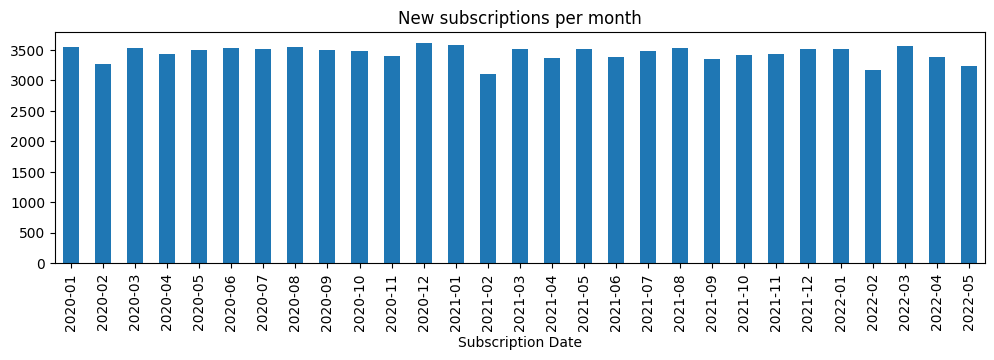

In [11]:
with track("subscription date"):
    df["Subscription Date"] = pd.to_datetime(df["Subscription Date"], errors="coerce")
    sub = df["Subscription Date"]
    monthly = sub.dt.to_period("M").value_counts().sort_index()   # chronological order
    weekday = sub.dt.day_name().value_counts()

print("------------------------")
print("Range:", sub.min().date(), "->", sub.max().date(), "| invalid dates:", sub.isna().sum())
print("------------------------")
display(monthly)
monthly.plot(kind="bar", figsize=(12, 3), title="New subscriptions per month")
print("------------------------")
display(weekday)

Subscriptions run from 2020-01-01 to 2022-05-29 (29 months). The number of new subscriptions per month is stable, between 3,106 and 3,616, with no clear upward or downward trend. The same holds for the day of the week: each weekday has between 14,147 and 14,417 subscriptions in total.

## Email & Website

In [12]:
with track("email & website"):
    email_domain = df["Email"].str.split("@").str[1].str.lower()
    tld = df["Website"].str.extract(r"\.([a-z]+)/?$", expand=False)

print("------------------------")
print("Unique email domains:", email_domain.nunique())
print("------------------------")
display(email_domain.value_counts().head(10))
print("------------------------")
display(tld.value_counts(normalize=True).round(3) * 100)

[email & website] peak memory: 38.7 MB | time: 0.98 seconds
------------------------
Unique email domains: 38322
------------------------


Email
mckee.com          59
pugh.com           59
terrell.com        57
lawrence.com       57
gaines.com         56
delgado.com        56
romero.com         56
fitzpatrick.com    55
glass.com          55
jacobson.com       55
Name: count, dtype: int64

------------------------


Website
com     60.0
net     10.1
info    10.0
biz     10.0
org      9.9
Name: proportion, dtype: float64

From these results, emails are spread over 38,322 domains, and none of them is dominant (the most common domain has only 59 customers). For websites, 60% end with '.com', and the other domains ('.net', '.info', '.biz', '.org') each account for about 10%.

## Time & Memory

Every section above is measured with `track`. The results are saved to `results-100k.csv`, so they can be compared with `coding-2.ipynb` in question number 3.

In [13]:
# Save every measurement, to be compared with coding-2 in question number 3
df_results = pd.DataFrame(results)
df_results["file"] = "100k"
df_results.to_csv("results-100k.csv", index=False)
display(df_results)

,label,peak_mb,time_s,file
0,read csv (time only),NaN,0.50,100k
1,read csv,54.8,1.16,100k
2,data quality,13.7,0.70,100k
3,duplicate emails,2.2,0.03,100k
4,country,0.3,0.01,100k
5,country (time only),NaN,0.01,100k
6,phone patterns,10.7,3.58,100k
7,split phone,33.3,3.00,100k
8,country code by country,14.4,1.25,100k
9,subscription date,11.4,0.24,100k


## Conclusion

1. **The data is complete and well-structured.** The file has 100,000 rows and 12 columns (66.9 MB in memory) and loads in about 0.5 seconds. There are no missing values, no duplicate rows, and every Customer ID is unique.
2. **Email is not a unique identifier.** 5 email addresses are each shared by two different customers in different countries, so Customer ID should be used as the customer key instead.
3. **Customers are spread evenly across countries.** There are 243 countries with an average of 412 customers each, and almost every country is close to that number. The exceptions are Congo (835) and Korea (820), which have about twice the average; a possible reason is that each name covers two countries (e.g. North and South Korea).
4. **Phone numbers are inconsistent and do not reflect the customer's country.** Each phone column uses 21 different formats, and 60% of the numbers include an extension. The only country code found is '+1' (US/Canada), and it appears at a similar rate in every country.
5. **Subscriptions show no trend.** Between January 2020 and May 2022, new subscriptions stay between 3,106 and 3,616 per month and are almost equal on every day of the week.
6. **Emails and websites are highly diverse.** Emails come from 38,322 different domains with no dominant one, and 60% of websites use '.com'.

**Overall:** the dataset is clean, but its distributions are almost perfectly uniform and the phone country codes do not match the customers' countries. These are strong signs that the data is **synthetic (randomly generated)**. It is suitable for testing data pipelines, but it should not be used to draw conclusions about real customer behavior.